(which-grade-to-put-on-the-bottle)=
# White-wine grade probabilities

A white Vinho Verde is scored by a sensory panel on an ordered grade. The lab already has the chemistry. The decision is the probability of each grade, not a mean that falls between grades and not a yes-or-no call on whether the wine is "good."

The file is the white-wine half of the UCI Wine Quality data, Cortez, Cerdeira, Almeida, Matos and Reis, Decision Support Systems 47(4):547-553 (2009), retrieved 2026-10-04 from `https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv`. The UCI file is semicolon-separated. `quality` is the median of at least three sensory grades. Red wines are a different product and are not in this file.

Grades 3 and 9 are too rare to hold out (20 wines and 5). Grade 3 is pooled with 4, and grade 9 with 8, so the published scale is 4, 5, 6, 7, 8. The candidates are an ordered logit, an ordered probit, an unordered multinomial logit, a constant grade distribution, a linear regression on the grade number, and proportional-odds boosting. Wines are split by grade.


:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | the probability of each sensory grade |
| **Observed response** | the panel median, pooled at the two tails |
| **Estimand** | held-out log loss of the grade, and absolute error of the expected grade number |
| **Units** | nats per wine, lower is better; grade steps |
| **Sampling unit** | one row is one white wine with chemistry and a pooled sensory grade |
| **Dependence** | The working likelihood treats wine records as conditionally independent; no producer or batch clustering is estimated. |
| **Split and tuning** | wines, stratified by grade; 20% choose steps, 20% held out, refit on the rest |
| **Information** | the eleven lab measurements shipped with the file |
| **Uncertainty** | fitted predictive distributions are scored; no resampling confidence intervals for score differences are reported |
| **Claim type** | predictive comparisons conditional on the recorded covariates; no causal effects are estimated |
| **What this does not estimate** | a price, a red wine, or a grade for a wine this panel never scored |

:::


In [1]:
import warnings
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl
import statsmodels.formula.api as smf
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from statsmodels.miscmodels.ordinal_model import OrderedModel

import mboostrs as mb

path = Path("wine_quality_white.csv")
if not path.exists():
    path = Path("docs/book/case_studies/wine_quality_white.csv")
raw = pl.read_csv(path, comment_prefix="#")
quality = pl.col("quality")
frame = raw.with_columns(
    pl.when(quality <= 4).then(4).when(quality >= 8).then(8).otherwise(quality).alias("grade")
)
predictors = [
    "fixed_acidity", "volatile_acidity", "citric_acid", "residual_sugar", "chlorides",
    "free_sulfur_dioxide", "total_sulfur_dioxide", "density", "ph", "sulphates", "alcohol",
]
formula = "grade ~ " + " + ".join(predictors)
grades = [4, 5, 6, 7, 8]
rng = np.random.default_rng(20261004)
indexed = frame.with_row_index("i")
parts = []
for grade in grades:
    ids = indexed.filter(pl.col("grade") == grade)["i"].to_numpy().copy()
    rng.shuffle(ids)
    n = len(ids)
    n_test = int(round(0.20 * n))
    n_valid = int(round(0.20 * n))
    parts.append((ids[n_test + n_valid :], ids[n_test : n_test + n_valid], ids[:n_test]))
train_ids = np.concatenate([p[0] for p in parts])
valid_ids = np.concatenate([p[1] for p in parts])
test_ids = np.concatenate([p[2] for p in parts])
train = frame[train_ids.tolist()]
valid = frame[valid_ids.tolist()]
fit_rows = frame[np.concatenate([train_ids, valid_ids]).tolist()]
test = frame[test_ids.tolist()]
print(
    f"{frame.height} wines; grades "
    + ", ".join(f"{g}={int((frame['grade']==g).sum())}" for g in grades)
    + f"; {train.height} to fit the path, {valid.height} to choose steps, "
    f"{fit_rows.height} refit, {test.height} held out"
)


4898 wines; grades 4=183, 5=1457, 6=2198, 7=880, 8=180; 2938 to fit the path, 980 to choose steps, 3918 refit, 980 held out


In [2]:
def design(data):
    return np.column_stack([data[name].to_numpy() for name in predictors])


def columns_of(data):
    out = {name: data[name].to_numpy() for name in predictors}
    out["grade"] = data["grade"].to_numpy().astype(float)
    return out


def log_loss(grade, probability):
    grade = np.asarray(grade)
    probability = np.asarray(probability, dtype=float)
    column = np.array([grades.index(int(value)) for value in grade])
    chosen = probability[np.arange(len(grade)), column]
    return float(-np.mean(np.log(np.clip(chosen, 1e-12, 1.0))))


def expected_grade(probability):
    return np.asarray(probability, dtype=float) @ np.asarray(grades, dtype=float)


def grade_mae(grade, probability):
    return float(np.mean(np.abs(np.asarray(grade, dtype=float) - expected_grade(probability))))


y_fit = fit_rows["grade"].to_numpy()
y_test = test["grade"].to_numpy()
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    ordered_logit = OrderedModel(y_fit, design(fit_rows), distr="logit").fit(method="bfgs", disp=False)
    ordered_probit = OrderedModel(y_fit, design(fit_rows), distr="probit").fit(method="bfgs", disp=False)
    ols = smf.ols(formula, columns_of(fit_rows)).fit()
    center = design(fit_rows).mean(axis=0)
    scale = design(fit_rows).std(axis=0)
    scale[scale == 0] = 1.0
    multinomial = LogisticRegression(C=np.inf, solver="lbfgs", max_iter=1000)
    multinomial.fit((design(fit_rows) - center) / scale, y_fit)

logit_p = np.asarray(ordered_logit.model.predict(ordered_logit.params, exog=design(test)))
probit_p = np.asarray(ordered_probit.model.predict(ordered_probit.params, exog=design(test)))
sk_order = [list(multinomial.classes_).index(grade) for grade in grades]
multi_p = multinomial.predict_proba((design(test) - center) / scale)[:, sk_order]
ols_mu = np.asarray(ols.predict(columns_of(test)), dtype=float)
shares = np.array([(y_fit == grade).mean() for grade in grades])
constant_p = np.tile(shares, (len(y_test), 1))
logit_converged = bool(ordered_logit.mle_retvals.get("converged"))
probit_converged = bool(ordered_probit.mle_retvals.get("converged"))
multi_iter = int(np.max(multinomial.n_iter_))


In [3]:
def operating_step(curve, tolerance):
    best = min(score for _, score in curve)
    step = min(k for k, score in curve if score <= best + tolerance)
    last_step, last_score = curve[-1]
    earlier = [score for k, score in curve if k <= last_step - 80]
    still_falling = bool(earlier) and earlier[-1] - last_score > 0.005 and last_score <= best + 1e-12
    return step, still_falling


y_valid = valid["grade"].to_numpy()
family = mb.PropOdds(levels=grades)
path = mb.glmboost(formula, train, family=family, control=mb.boost_control(400, 0.1))
curve = []
for step in range(40, 401, 40):
    probability = np.asarray(path.with_mstop(step).predict(valid, type="response"))
    curve.append((step, log_loss(y_valid, probability)))
step_prop, prop_at_cap = operating_step(curve, 0.005)
print("proportional-odds steps", step_prop, "still falling", prop_at_cap, "curve", [(k, round(s, 4)) for k, s in curve])


proportional-odds steps 320 still falling False curve [(40, 1.1812), (80, 1.1566), (120, 1.1465), (160, 1.1395), (200, 1.134), (240, 1.1297), (280, 1.1264), (320, 1.1237), (360, 1.1216), (400, 1.1199)]


In [4]:
prop_fit = mb.glmboost(formula, fit_rows, family=family, control=mb.boost_control(step_prop, 0.1))
prop_p = np.asarray(prop_fit.predict(test, type="response"))
rows = []


def add(method, loss, error, mstop=None, at_cap=None, note=""):
    rows.append({"method": method, "log_loss": loss, "mae": error, "mstop": mstop, "at_cap": at_cap, "note": note})


add("ordered logit", log_loss(y_test, logit_p), grade_mae(y_test, logit_p), note=f"converged {logit_converged}")
add("ordered probit", log_loss(y_test, probit_p), grade_mae(y_test, probit_p), note=f"converged {probit_converged}")
add("sklearn multinomial logit", log_loss(y_test, multi_p), grade_mae(y_test, multi_p), note=f"scaled chemistry; iterations {multi_iter}")
add("glmboost PropOdds", log_loss(y_test, prop_p), grade_mae(y_test, prop_p), mstop=step_prop, at_cap=prop_at_cap, note="")
add("training grade shares", log_loss(y_test, constant_p), grade_mae(y_test, constant_p), note="")
add("statsmodels OLS", None, float(np.mean(np.abs(y_test - ols_mu))), note=f"mean prediction {float(np.mean(ols_mu)):.2f}")
summary = pl.DataFrame(rows).sort("log_loss", nulls_last=True)
display(summary)
probability_rows = float(np.max(np.abs(prop_p.sum(axis=1) - 1.0)))


method,log_loss,mae,mstop,at_cap,note
str,f64,f64,i64,bool,str
"""ordered logit""",1.085117,0.568517,null,null,"""converged True"""
"""sklearn multinomial logit""",1.086765,0.567176,null,null,"""scaled chemistry; iterations 8…"
"""glmboost PropOdds""",1.092953,0.57695,320,false,""""""
"""ordered probit""",1.102158,0.569869,null,null,"""converged True"""
"""training grade shares""",1.273543,0.664833,null,null,""""""
"""statsmodels OLS""",null,0.572649,null,null,"""mean prediction 5.86"""


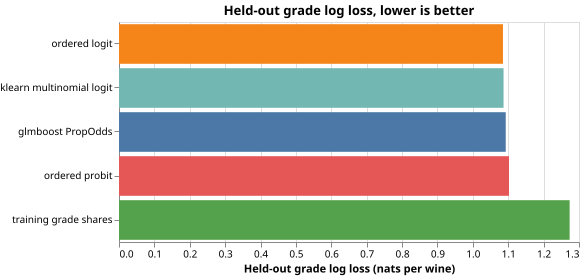

In [5]:
scored = summary.filter(pl.col("log_loss").is_not_null())
alt.Chart(scored).mark_bar().encode(
    x=alt.X("log_loss:Q", title="Held-out grade log loss (nats per wine)", scale=alt.Scale(zero=False)),
    y=alt.Y("method:N", sort="x", title=None),
    color=alt.Color("method:N", legend=None),
).properties(width=460, height=220, title="Held-out grade log loss, lower is better")


band,observed,ordered_logit
str,f64,f64
"""bottom quarter of alcohol""",0.063973,0.065342
"""top quarter of alcohol""",0.473684,0.433954


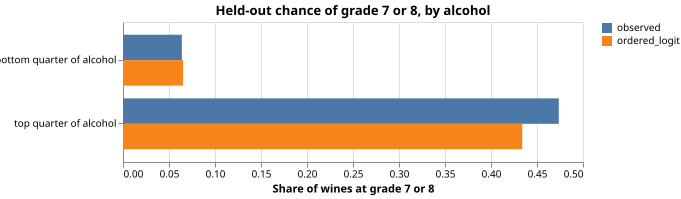

In [6]:
alcohol_cut = float(np.quantile(fit_rows["alcohol"].to_numpy(), 0.75))
alcohol_floor = float(np.quantile(fit_rows["alcohol"].to_numpy(), 0.25))
test_alcohol = test["alcohol"].to_numpy()
high_cut = test_alcohol >= alcohol_cut
low_cut = test_alcohol <= alcohol_floor
observed_high = (y_test >= 7).astype(float)
bands = pl.DataFrame({
    "band": ["bottom quarter of alcohol", "top quarter of alcohol"],
    "observed": [float(observed_high[low_cut].mean()), float(observed_high[high_cut].mean())],
    "ordered_logit": [float((logit_p[low_cut, 3] + logit_p[low_cut, 4]).mean()), float((logit_p[high_cut, 3] + logit_p[high_cut, 4]).mean())],
})
display(bands)
band_chart = bands.unpivot(index="band", on=["observed", "ordered_logit"], variable_name="source", value_name="share")
alt.Chart(band_chart).mark_bar().encode(
    x=alt.X("share:Q", title="Share of wines at grade 7 or 8"),
    y=alt.Y("band:N", title=None),
    color=alt.Color("source:N", title=None),
    yOffset="source:N",
).properties(width=460, height=140, title="Held-out chance of grade 7 or 8, by alcohol")


## Results and interpretation

Publish the ordered logit. On the held-out wines its grade log loss is {eval}`f"{float(summary.filter(pl.col('method')=='ordered logit')['log_loss'][0]):.3f}"` nats and the absolute error of its expected grade is {eval}`f"{float(summary.filter(pl.col('method')=='ordered logit')['mae'][0]):.3f}"` steps. The training shares score {eval}`f"{float(summary.filter(pl.col('method')=='training grade shares')['log_loss'][0]):.3f}"`. The lower log loss measures the predictive contribution of the chemistry
relative to training grade shares on these held-out wines. The ordered probit scores {eval}`f"{float(summary.filter(pl.col('method')=='ordered probit')['log_loss'][0]):.3f}"`. Both report converged. The two links give similar held-out grade probabilities by this score.

The unordered multinomial, with the chemistry scaled and no penalty, scores {eval}`f"{float(summary.filter(pl.col('method')=='sklearn multinomial logit')['log_loss'][0]):.3f}"`. Its absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='sklearn multinomial logit')['mae'][0]):.3f}"` against {eval}`f"{float(summary.filter(pl.col('method')=='ordered logit')['mae'][0]):.3f}"` for the ordered logit. A separate slope for every cut does not improve the grade probabilities enough to publish four equations. One proportional-odds slope is the model. Proportional-odds boosting, {eval}`str(int(summary.filter(pl.col('method')=='glmboost PropOdds')['mstop'][0]))` steps, scores {eval}`f"{float(summary.filter(pl.col('method')=='glmboost PropOdds')['log_loss'][0]):.3f}"`. At this stopping point its log loss remains above the maximum-likelihood
ordered-logit fit.

Do not publish the linear regression. Its absolute error is {eval}`f"{float(summary.filter(pl.col('method')=='statsmodels OLS')['mae'][0]):.3f}"`, close to the ordered logit, but the number it prints is a mean of {eval}`f"{float(np.mean(ols_mu)):.2f}"`. That is not a grade on this scale. The bottle needs the probability of 4, 5, 6, 7, and 8.

Volatile acidity is the sharp partial effect: {eval}`f"{float(ordered_logit.params[1]):.2f}"` on the latent logit per unit, standard error {eval}`f"{float(ordered_logit.bse[1]):.2f}"`. Alcohol is {eval}`f"{float(ordered_logit.params[10]):.2f}"` per unit of alcohol, standard error {eval}`f"{float(ordered_logit.bse[10]):.2f}"`, and it survives with density and sugar in the same equation. Density's coefficient is {eval}`f"{float(ordered_logit.params[7]):.0f}"` because specific gravity only moves in the thousandths. Do not quote that number per 1.0. In the held-out wines, the bottom quarter of alcohol has an observed grade-7-or-8 share of {eval}`f"{float(bands['observed'][0]):.0%}"` and the ordered logit says {eval}`f"{float(bands['ordered_logit'][0]):.0%}"`. The top quarter is observed at {eval}`f"{float(bands['observed'][1]):.0%}"` and predicted at {eval}`f"{float(bands['ordered_logit'][1]):.0%}"`.

This is the grade distribution for a white Vinho Verde with this lab panel. It is not a red wine, not a price, and not a wine the panel never scored. Grades 3 and 9 are inside the codes 4 and 8.


In [7]:
train_p = np.asarray(prop_fit.predict(type="response"))
y_refit = fit_rows["grade"].to_numpy()
column = np.array([grades.index(int(value)) for value in y_refit])
hand = float(np.sum(np.log(np.clip(train_p[np.arange(len(y_refit)), column], 1e-300, 1.0))))
prop_ll_gap = abs(float(prop_fit.logLik()) - hand)
print("logLik gap", prop_ll_gap)
print("row sum", probability_rows)
print("at cap", prop_at_cap)


logLik gap 4.547473508864641e-12
row sum 1.1102230246251565e-16
at cap False


## API behavior and limitations

`PropOdds` `type="response"` is an array with one column per grade, in the order of `levels`. On this fit the rows sum to one within {eval}`f"{probability_rows:.1e}"`. `logLik()` matches the categorical log likelihood of those probabilities to {eval}`f"{prop_ll_gap:.1e}"`. `predict` with no `type` is not that matrix.

`OrderedModel` is fit without an intercept column. The cutpoints are the extra parameters after the eleven chemistry slopes. `predict` returns the grade probabilities in sorted grade order, which here is 4, 5, 6, 7, 8. The multinomial row is the same chemistry after subtracting the refit-sample mean and dividing by its standard deviation. The ordered logit and probit are on the original units.
